# 06 · Risultati, sensibilità e prestazioni

**Domanda di ricerca.** Una strategia di market making short term, attiva nei periodi di bassa volatilità, conserva una profittabilità positiva quando le euristiche L2 vengono sostituite da un modello queue aware basato su dati L3 e L4?

**Criterio (piano, §5.2).** La strategia è economicamente sostenibile solo se il P&L netto resta positivo nel test set, l'inventario è controllato e il risultato non dipende da una sola giornata. Un P&L positivo solo con `touch` non è evidenza sufficiente.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")
validation = R.load(ROOT, "validation")
selected = R.load_json(ROOT, "selected_params")

order = [m for m in R.MODEL_ORDER]
rows = []
for name in ["fi2010", "itch", "hyperliquid"]:
    spec_fee = {"fi2010": None, "itch": "net_nasdaq_base", "hyperliquid": "net_tier0"}[name]
    frame = test[test.dataset == name]
    for model, g in frame.groupby("model"):
        value = g[spec_fee] if spec_fee else g.final_equity
        from market_making_tesi.evaluation import bootstrap_mean_ci
        mean, low, high = bootstrap_mean_ci(value)
        rows.append({"dataset": R.DATASET_LABELS[name], "modello": R.LABELS[model], "sessioni": len(g),
                     "P&L netto medio": mean, "IC95 basso": low, "IC95 alto": high,
                     "sessioni positive": (value > 0).mean(), "fill maker medi": g.maker_fills.mean(),
                     "inventario max": g.max_abs_inventory_seen.max()})
overview = pd.DataFrame(rows)
overview["_o"] = overview.modello.map({R.LABELS[m]: i for i, m in enumerate(order)})
overview = overview.sort_values(["dataset", "_o"]).drop(columns="_o").set_index(["dataset", "modello"])
overview.to_csv(ROOT / "results" / "tabella_riepilogo.csv")
display(overview.style.format({"P&L netto medio": "{:,.2f}", "IC95 basso": "{:,.2f}", "IC95 alto": "{:,.2f}",
                               "sessioni positive": "{:.0%}", "fill maker medi": "{:,.0f}", "inventario max": "{:g}"}))

## Metriche di attività e rischio (piano, §5.1)

Medie per sessione di test: P&L per coppia quotata (opportunità di quotazione), quota di coppie con entrambi i lati eseguiti, turnover (controvalore scambiato), drawdown massimo della curva di equity e markout medio per unità dopo i fill in acquisto e in vendita.

In [2]:
metrics = test.groupby(["dataset", "model"]).agg(
    pnl_per_coppia=("pnl_per_pair", "mean"), coppie_bilaterali=("fill_rate_pairs", "mean"),
    turnover=("turnover", "mean"), drawdown_max=("max_drawdown", "mean"),
    markout_bid=("markout_bid_mean", "mean"), markout_ask=("markout_ask_mean", "mean"),
    sospensioni_volatilita=("halted_records", "mean")).reset_index()
metrics["dataset"] = metrics.dataset.map(R.DATASET_LABELS)
metrics["model"] = metrics.model.map(R.LABELS)
display(metrics.set_index(["dataset", "model"]).style.format("{:,.4g}"))

## Filtro di volatilità (ablazione)

La domanda di ricerca riguarda una strategia *attiva nei periodi di bassa volatilità*. La tabella confronta, per ogni dataset e con il modello di riferimento, la strategia con filtro e la stessa strategia sempre attiva sulle stesse sessioni di test (differenza appaiata, IC bootstrap 95%).

In [3]:
ablation = R.load(ROOT, "ablation")
filter_rows = []
for name, value, ref in [("fi2010", "final_equity", "price-through"), ("itch", "net_nasdaq_base", "queue"),
                         ("hyperliquid", "net_tier0", "queue")]:
    eff = R.filter_effect(test, ablation, name, value)
    for model in [ref, "touch"]:
        r = eff.loc[R.LABELS[model]]
        filter_rows.append({"dataset": R.DATASET_LABELS[name], "modello": R.LABELS[model], **r.to_dict()})
filters = pd.DataFrame(filter_rows).set_index(["dataset", "modello"])
filters.to_csv(ROOT / "results" / "tabella_filtro_volatilita.csv")
display(filters[["sessioni", "con filtro", "sempre attiva", "differenza", "IC95 basso", "IC95 alto",
                 "sessioni migliori con filtro", "quota record attivi"]].style.format(
    {c: "{:,.4g}" for c in ["con filtro", "sempre attiva", "differenza", "IC95 basso", "IC95 alto"]}
    | {"sessioni migliori con filtro": "{:.0%}", "quota record attivi": "{:.0%}"}))

## Estensioni: inventory skew e filtro di imbalance

Due varianti della regola base, con parametri scelti in validazione a parità di parametri base:

* **inventory skew**: dopo un fill su un solo lato non si liquida a mercato alla scadenza; si mantiene una quota passiva solo sul lato che riduce l'inventario, al best migliorato di *k* tick quando lo spread lo consente, e si liquida a mercato solo dopo un tempo massimo di detenzione;
* **filtro di imbalance**: con I = (q_bid − q_ask)/(q_bid + q_ask) al best, si apre una coppia solo se |I| ≤ θ e si cancella una quota quando l'imbalance la minaccia (I > θ per una vendita, I < −θ per un acquisto).

La tabella riporta il P&L netto con coda FIFO e la differenza appaiata con la strategia base. Per FI-2010 non esiste un replay a coda: il riferimento è `price-through`, una regola L2 che questa stessa tesi mostra essere distorta, quindi un risultato positivo su FI-2010 **non è evidenza** di profittabilità.

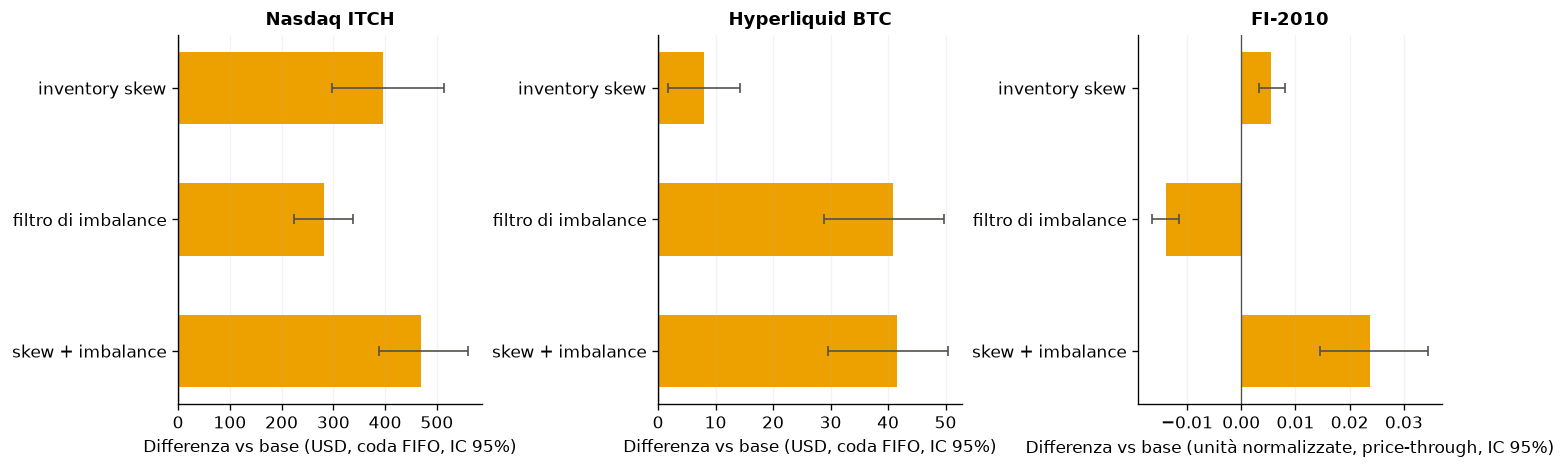

**Il bias di esecuzione resta con le varianti** (P&L lordo medio per sessione)

**Variante migliore con latenza su inserimenti e cancellazioni** (coda FIFO)

In [4]:
variants = R.load(ROOT, "variants")
variant_rows = []
for name, value, ref, fee in [("fi2010", "final_equity", "price-through", None),
                              ("itch", "net_nasdaq_base", "queue", "fees_nasdaq_base"),
                              ("hyperliquid", "net_tier0", "queue", "fees_tier0")]:
    eff = R.variant_effect(test, variants, name, value, model=ref, fee_column=fee)
    eff.insert(0, "dataset", R.DATASET_LABELS[name])
    variant_rows.append(eff.reset_index())
variant_table = pd.concat(variant_rows).set_index(["dataset", "variante"])
variant_table.to_csv(ROOT / "results" / "tabella_varianti.csv")
cols = ["sessioni", "P&L netto medio", "IC95 basso", "IC95 alto", "sessioni positive",
        "differenza vs base", "diff IC95 basso", "diff IC95 alto", "liquidazioni a mercato", "coppie bilaterali"]
display(variant_table[cols].style.format({c: "{:,.4g}" for c in cols[1:4] + cols[5:9]} | {"sessioni positive": "{:.0%}", "coppie bilaterali": "{:.0%}"}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, name in zip(axes, ["Nasdaq ITCH", "Hyperliquid BTC", "FI-2010"]):
    t = variant_table.loc[name].drop(index="base")
    y = np.arange(len(t))[::-1]
    ax.barh(y, t["differenza vs base"], color=R.COLORS["queue"], height=0.55)
    ax.errorbar(t["differenza vs base"], y, xerr=[t["differenza vs base"] - t["diff IC95 basso"],
                t["diff IC95 alto"] - t["differenza vs base"]], fmt="none", ecolor=R.INK, capsize=3, linewidth=1)
    ax.set_yticks(y, t.index)
    ax.axvline(0, color=R.INK, linewidth=0.8)
    unit = "unità normalizzate, price-through" if name == "FI-2010" else "USD, coda FIFO"
    ax.set(title=name, xlabel=f"Differenza vs base ({unit}, IC 95%)")
    ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "varianti_strategia.png", dpi=180, bbox_inches="tight")
plt.show()

bias_rows = []
for name in ["itch", "hyperliquid"]:
    for variant in ["base", "skew", "imbalance", "skew_imbalance"]:
        frame = test if variant == "base" else variants[variants.variant == variant]
        ratio = R.fill_bias(frame, name).median()
        bias_rows.append({"dataset": R.DATASET_LABELS[name], "variante": R.VARIANT_LABELS[variant],
                          "fill touch / coda": ratio["touch"],
                          "P&L touch": frame[(frame.dataset == name) & (frame.model == "touch")].final_equity.mean(),
                          "P&L coda": frame[(frame.dataset == name) & (frame.model == "queue")].final_equity.mean()})
display(Markdown("**Il bias di esecuzione resta con le varianti** (P&L lordo medio per sessione)"))
display(pd.DataFrame(bias_rows).set_index(["dataset", "variante"]).style.format("{:,.1f}"))

vstress = R.load(ROOT, "variants_stress")
latency_rows = []
for name, col, unit, fee, scale in [("itch", "param_latency_ns", "ms", "net_nasdaq_base", 1e6),
                                     ("hyperliquid", "param_latency_events", "eventi", "net_tier0", 1)]:
    g = vstress[vstress.dataset == name]
    for value, h in g.groupby(col):
        latency_rows.append({"dataset": R.DATASET_LABELS[name], "variante": R.VARIANT_LABELS[h.variant.iloc[0]],
                             "latenza": f"{it(value / scale, 0 if value == 0 or value / scale >= 1 else 1)} {unit}",
                             "P&L netto medio": h[fee].mean(), "sessioni positive": (h[fee] > 0).mean(),
                             "fill maker": h.maker_fills.mean(), "rifiuti post-only": h.post_only_rejects.mean()})
latency_table = pd.DataFrame(latency_rows).set_index(["dataset", "variante", "latenza"])
display(Markdown("**Variante migliore con latenza su inserimenti e cancellazioni** (coda FIFO)"))
display(latency_table.style.format({"P&L netto medio": "{:,.2f}", "sessioni positive": "{:.0%}",
                                    "fill maker": "{:,.0f}", "rifiuti post-only": "{:,.0f}"}))

## Bias di esecuzione delle regole L2

Rapporto tra i fill maker di ciascuna regola L2 e quelli della coda FIFO nella stessa sessione (ITCH, Hyperliquid), e distanza del P&L lordo dal replay a coda.

fill / coda (mediana)  \
dataset         modello                                
Nasdaq ITCH     touch                         105.99   
                price-through                   1.09   
                cross                           1.05   
Hyperliquid BTC touch                        2371.72   
                price-through                   1.33   
                cross                           1.10   

                               P&L L2 - P&L coda (media)  
dataset         modello                                   
Nasdaq ITCH     touch                          112678.22  
                price-through                      36.69  
                cross                            -830.64  
Hyperliquid BTC touch                            3817.50  
                price-through                     -29.33  
                cross                             -25.35

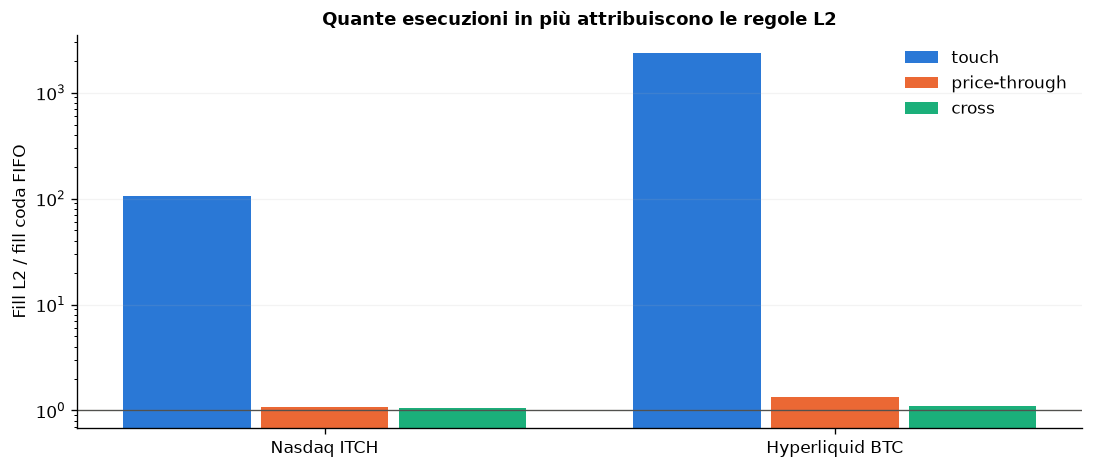

In [5]:
bias_rows = []
for name in ["itch", "hyperliquid"]:
    ratios = R.fill_bias(test, name)
    frame = test[test.dataset == name].pivot_table(index=["session", "symbol"], columns="model", values="final_equity")
    for model in ["touch", "price-through", "cross"]:
        bias_rows.append({"dataset": R.DATASET_LABELS[name], "modello": R.LABELS[model],
                          "fill / coda (mediana)": ratios[model].median(),
                          "P&L L2 - P&L coda (media)": (frame[model] - frame["queue"]).mean()})
bias = pd.DataFrame(bias_rows)
display(bias.set_index(["dataset", "modello"]).round(2))
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
names = bias.dataset.unique()
x = np.arange(len(names))
for i, model in enumerate(["touch", "price-through", "cross"]):
    vals = bias[bias.modello == R.LABELS[model]].set_index("dataset").loc[names, "fill / coda (mediana)"]
    ax.bar(x + (i - 1) * 0.27, vals, 0.25, color=R.COLORS[model], label=R.LABELS[model])
ax.axhline(1, color=R.INK, linewidth=0.8)
ax.set_xticks(x, names)
ax.set(yscale="log", ylabel="Fill L2 / fill coda FIFO", title="Quante esecuzioni in più attribuiscono le regole L2")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "bias_esecuzione.png", dpi=180, bbox_inches="tight")
plt.show()

## Costi, liquidazione e latenza (E5)

Le commissioni e la regola di liquidazione non cambiano le decisioni della strategia: il P&L con liquidazione al midpoint (limite teorico) si ottiene togliendo il costo di liquidazione, quello netto sottraendo le commissioni calcolate sui fill. La latenza invece cambia le esecuzioni ed è simulata: la quota entra nel mercato e viene cancellata con ritardo, e se all'attivazione attraverserebbe il book viene rifiutata (post-only).

,liquidazione al midpoint,netto lordo,netto nasdaq_base,netto senza_rebate,netto tier0,netto tier_alto
dataset,,,,,,
Nasdaq ITCH,-301.68,-570.29,-540.59,-674.28,NaN,NaN
Hyperliquid BTC,-1.97,-3.25,NaN,NaN,-47.28,-16.08


,netto,fill,rifiuti
latenza (ms),,,
0.0,-540.59,1070.87,0.00
1000000.0,-500.45,1025.53,51.20
10000000.0,-540.48,1012.73,62.00
100000000.0,-549.89,994.47,69.07


,netto,fill,rifiuti
latenza (eventi),,,
0.0,-47.28,308.50,0.00
50.0,-45.67,295.75,16.75
500.0,-31.40,204.75,133.00


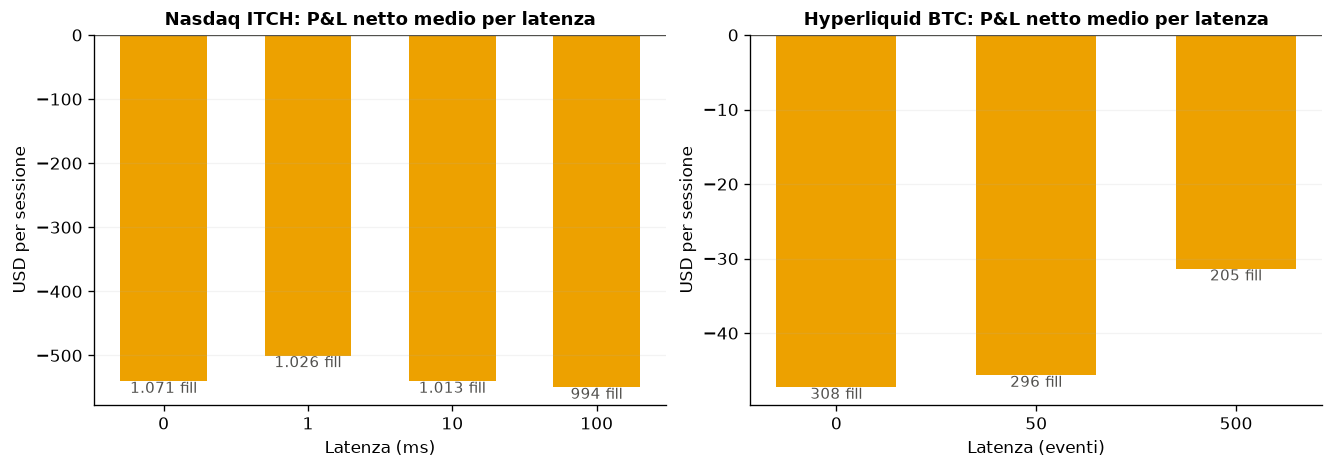

In [6]:
queue = test[test.model == "queue"]
scen = []
for name, fees in [("itch", ["lordo", "nasdaq_base", "senza_rebate"]),
                   ("hyperliquid", ["lordo", "tier0", "tier_alto"])]:
    g = queue[queue.dataset == name]
    row = {"dataset": R.DATASET_LABELS[name], "liquidazione al midpoint": g.pnl_midpoint_liquidation.mean()}
    row.update({f"netto {f}": g[f"net_{f}"].mean() for f in fees})
    scen.append(row)
display(pd.DataFrame(scen).set_index("dataset").round(2))

stress = R.load(ROOT, "stress")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, name, col, unit, fee, scale in [(axes[0], "itch", "param_latency_ns", "ms", "net_nasdaq_base", 1e6),
                                         (axes[1], "hyperliquid", "param_latency_events", "eventi", "net_tier0", 1)]:
    g = stress[stress.dataset == name]
    if g.empty:
        continue
    agg = g.groupby(col).agg(netto=(fee, "mean"), fill=("maker_fills", "mean"), rifiuti=("post_only_rejects", "mean"))
    labels = [it(v / scale, 0 if v / scale >= 1 or v == 0 else 1) for v in agg.index]
    ax.bar(labels, agg.netto, color=R.COLORS["queue"], width=0.6)
    for k, (v, f) in enumerate(zip(agg.netto, agg.fill)):
        ax.text(k, v, f"{it(f)} fill", ha="center", va="top" if v < 0 else "bottom", color=R.INK, fontsize=9)
    ax.axhline(0, color=R.INK, linewidth=0.8)
    ax.set(title=f"{R.DATASET_LABELS[name]}: P&L netto medio per latenza", xlabel=f"Latenza ({unit})", ylabel="USD per sessione")
    ax.grid(axis="x", visible=False)
    display(agg.round(2).rename_axis(f"latenza ({unit})"))
fig.savefig(FIGURES / "stress_latenza.png", dpi=180, bbox_inches="tight")
plt.show()

## Prestazioni del software

Tempo di elaborazione, throughput e memoria di picco per simulazione (ciascuna in un processo dedicato), e throughput del parser ITCH. La vista L2 dei dataset order-level richiede comunque la ricostruzione del book: il costo del maggiore dettaglio informativo sta soprattutto nel parsing e nella ricostruzione, non nella regola di fill.

In [7]:
perf = test.groupby(["dataset", "model"]).agg(simulazioni=("seconds", "size"), secondi_medi=("seconds", "mean"),
                                              record_medi=("records", "mean"), record_al_secondo=("records_per_second", "mean"),
                                              memoria_picco_MB=("peak_memory_mb", "max")).reset_index()
perf["dataset"] = perf.dataset.map(R.DATASET_LABELS)
perf["model"] = perf.model.map(R.LABELS)
display(perf.set_index(["dataset", "model"]).round(1))
itch_ingest = pd.DataFrame(R.load_json(ROOT, "ingest/itch")["sessions"])
display(pd.Series({"giornate ITCH": len(itch_ingest), "messaggi letti (milioni)": it(itch_ingest.messages.sum() / 1e6),
                   "secondi per GB": it(itch_ingest.seconds.mean(), 1),
                   "messaggi/s per processo (migliaia)": it(itch_ingest.messages_per_second.mean() / 1e3)}, name="parser ITCH").to_frame())

simulazioni  secondi_medi  record_medi  \
dataset         model                                                   
FI-2010         cross                   35           0.4       8225.5   
                price-through           35           0.4       8225.5   
                touch                   35           0.4       8225.5   
Hyperliquid BTC cross                    4          79.7    3827879.0   
                price-through            4          84.8    3827879.0   
                coda FIFO                4          77.1    3827879.0   
                touch                    4         145.8    3827879.0   
Nasdaq ITCH     cross                   15          28.3    1224871.2   
                price-through           15          28.4    1224871.2   
                coda FIFO               15          27.9    1224871.2   
                touch                   15          31.6    1224871.2   

                               record_al_secondo  memoria_picco_MB  
dataset         model                                               
FI-2010         cross                    22269.2             121.5  
                price-through            22219.5             121.9  
                touch                    20727.6             125.7  
Hyperliquid BTC cross                    46871.9             396.6  
                price-through            44020.3             395.7  
                coda FIFO                48617.3             400.1  
                touch                    26592.3             990.7  
Nasdaq ITCH     cross                    43125.3             345.9  
                price-through            42929.6             349.7  
                coda FIFO                43851.3             348.9  
                touch                    38269.6             420.2

,parser ITCH
giornate ITCH,7
messaggi letti (milioni),2.354
secondi per GB,"252,4"
messaggi/s per processo (migliaia),1.331


## Risposta alla domanda di ricerca

In [8]:
criteria = []
for name, fee in [("itch", "net_nasdaq_base"), ("hyperliquid", "net_tier0")]:
    g = queue[queue.dataset == name]
    limit = {"itch": 100, "hyperliquid": 0.01}[name]
    criteria.append({"dataset": R.DATASET_LABELS[name], "sessioni di test": len(g),
                     "P&L netto medio > 0": g[fee].mean() > 0,
                     "quota sessioni positive": g[fee].gt(0).mean(),
                     "inventario entro il limite": (g.max_abs_inventory_seen <= limit + 1e-9).all()})
criteria = pd.DataFrame(criteria).set_index("dataset")
display(criteria.style.format({"quota sessioni positive": "{:.0%}"}))
it_q = overview.loc[("Nasdaq ITCH", "coda FIFO")]
it_t = overview.loc[("Nasdaq ITCH", "touch")]
hl_q = overview.loc[("Hyperliquid BTC", "coda FIFO")]
sustainable = bool(criteria["P&L netto medio > 0"].any())
LABEL = {"maker_edge": "edge maker", "liquidation_cost": "costo di liquidazione",
         "inventory_pnl": "P&L di inventario (selezione avversa)", "fees": "commissioni"}
def drivers(name, fee):
    g = queue[queue.dataset == name]
    parts = {"maker_edge": g.maker_edge.mean(), "liquidation_cost": g.liquidation_cost.mean(),
             "inventory_pnl": g.inventory_pnl.mean(), "fees": -g[fee].mean()}
    neg = sorted((v, k) for k, v in parts.items() if v < 0)
    return ", ".join(f"{LABEL[k]} {it(v, 2)}" for v, k in neg), parts["maker_edge"]
itch_neg, itch_edge = drivers("itch", "fees_nasdaq_base")
fq = filters.xs("coda FIFO", level="modello")
parts = []
for ds, r in fq.iterrows():
    if r["sessioni"] < 2:
        parts.append(f"{ds}: una sola sessione, differenza {it(r['differenza'], 2)} non valutabile statisticamente "
                     f"(strategia attiva nel {pct(r['quota record attivi'], 0)} dei record)")
        continue
    sign = "migliora" if r["IC95 basso"] > 0 else ("peggiora" if r["IC95 alto"] < 0 else "non cambia in modo significativo")
    parts.append(f"{ds}: {sign} il P&L netto (differenza media {it(r['differenza'], 2)}, IC 95% {it(r['IC95 basso'], 2)}; "
                 f"{it(r['IC95 alto'], 2)}, migliore in {it(r['sessioni migliori con filtro'] * r['sessioni'])} sessioni su {it(r['sessioni'])}; "
                 f"strategia attiva nel {pct(r['quota record attivi'], 0)} dei record)")
vt = variant_table.drop(index="base", level="variante").loc[["Nasdaq ITCH", "Hyperliquid BTC"]]
best = vt.groupby(level="dataset")["P&L netto medio"].idxmax()
vparts = []
for ds, (_, variant) in best.items():
    r = vt.loc[(ds, variant)]
    sig = ("migliora in modo significativo" if r["diff IC95 basso"] > 0 else
           "peggiora in modo significativo" if r["diff IC95 alto"] < 0 else "non cambia in modo significativo")
    vparts.append(f"{ds}: la variante migliore è {variant} ({it(r['P&L netto medio'], 2)} USD netti per sessione, "
                  f"positiva nel {pct(r['sessioni positive'], 0)} delle sessioni), che {sig} il risultato rispetto alla base "
                  f"(differenza {it(r['differenza vs base'], 2)}, IC 95% {it(r['diff IC95 basso'], 2)}; {it(r['diff IC95 alto'], 2)})")
any_positive = bool((vt["IC95 basso"] > 0).any())
variant_text = ("; ".join(vparts) + (". Almeno una variante ha P&L netto positivo con intervallo di confidenza interamente sopra zero."
                if any_positive else ". Nessuna variante rende il P&L netto positivo in modo statisticamente affidabile."))
lt = latency_table.loc["Nasdaq ITCH"].reset_index()
zero, first, last = lt.iloc[0], lt.iloc[1], lt.iloc[-1]
variant_text += (f" Su ITCH la variante migliore ({first['variante']}) passa da {it(zero['P&L netto medio'], 2)} USD per sessione "
                 f"senza latenza a {it(first['P&L netto medio'], 2)} con {first['latenza']} e {it(last['P&L netto medio'], 2)} "
                 f"con {last['latenza']}: " + ("il beneficio dipende dalla rapidità delle cancellazioni."
                 if first['P&L netto medio'] < zero['P&L netto medio'] else "il risultato regge la latenza."))
filter_text = ("Rispetto alla stessa strategia sempre attiva, con coda FIFO il filtro " + "; ".join(parts)
               + (". Operare solo a bassa volatilità non basta a rendere positivo il risultato."
                  if (fq["con filtro"] <= 0).all() else "."))
hl_neg, hl_edge = drivers("hyperliquid", "fees_tier0")
display(Markdown(f"""
**Risposta.** {"Sì" if sustainable else "No"}: {"almeno un mercato soddisfa" if sustainable else "nessun mercato soddisfa"} il criterio del piano con il modello queue aware.
Su Nasdaq ITCH il P&L netto medio con coda FIFO è {it(it_q['P&L netto medio'], 1)} USD per sessione (IC 95% {it(it_q['IC95 basso'], 1)}; {it(it_q['IC95 alto'], 1)}),
positivo nel {pct(it_q['sessioni positive'], 0)} delle sessioni; la stessa strategia valutata con `touch` sulla vista L2 dello stesso feed
risulta positiva nel {pct(it_t['sessioni positive'], 0)} delle sessioni con {it(it_t['P&L netto medio'])} USD medi. Su Hyperliquid il P&L netto
con coda FIFO è {it(hl_q['P&L netto medio'], 2)} USD per ora. La profittabilità stimata dipende quindi dal modello di esecuzione: le euristiche L2,
e `touch` in particolare, attribuiscono esecuzioni che la coda non concede e trasformano in guadagno una strategia che, con fill realistici, perde.

Scomposizione media per sessione con coda FIFO. ITCH: edge maker {it(itch_edge, 2)} USD contro {itch_neg}.
Hyperliquid: edge maker {it(hl_edge, 2)} USD contro {hl_neg}.

**Filtro di volatilità.** {filter_text}

**Varianti.** {variant_text}

**Limiti.** Sette giornate ITCH (cinque di test, le uniche pubblicate da Nasdaq), sei ore per Hyperliquid; nessun impatto degli ordini virtuali
sul flusso storico; latenza modellata come ritardo costante; tariffe indicative. I risultati misurano la distorsione del backtest, non la
redditività di strategie più evolute.
"""))

,sessioni di test,P&L netto medio > 0,quota sessioni positive,inventario entro il limite
dataset,,,,
Nasdaq ITCH,15,False,0%,True
Hyperliquid BTC,4,False,0%,True



**Risposta.** No: nessun mercato soddisfa il criterio del piano con il modello queue aware.
Su Nasdaq ITCH il P&L netto medio con coda FIFO è -540,6 USD per sessione (IC 95% -659,6; -434,8),
positivo nel 0% delle sessioni; la stessa strategia valutata con `touch` sulla vista L2 dello stesso feed
risulta positiva nel 100% delle sessioni con 139.086 USD medi. Su Hyperliquid il P&L netto
con coda FIFO è -47,28 USD per ora. La profittabilità stimata dipende quindi dal modello di esecuzione: le euristiche L2,
e `touch` in particolare, attribuiscono esecuzioni che la coda non concede e trasformano in guadagno una strategia che, con fill realistici, perde.

Scomposizione media per sessione con coda FIFO. ITCH: edge maker 437,02 USD contro P&L di inventario (selezione avversa) -738,69, costo di liquidazione -268,61.
Hyperliquid: edge maker 0,59 USD contro commissioni -44,04, P&L di inventario (selezione avversa) -2,57, costo di liquidazione -1,27.

**Filtro di volatilità.** Rispetto alla stessa strategia sempre attiva, con coda FIFO il filtro Nasdaq ITCH: migliora il P&L netto (differenza media 151,17, IC 95% 59,66; 259,48, migliore in 12 sessioni su 15; strategia attiva nel 71% dei record); Hyperliquid BTC: migliora il P&L netto (differenza media 75,05, IC 95% 22,26; 127,84, migliore in 4 sessioni su 4; strategia attiva nel 32% dei record). Operare solo a bassa volatilità non basta a rendere positivo il risultato.

**Varianti.** Hyperliquid BTC: la variante migliore è skew + imbalance (-5,64 USD netti per sessione, positiva nel 0% delle sessioni), che migliora in modo significativo il risultato rispetto alla base (differenza 41,65, IC 95% 29,50; 50,35); Nasdaq ITCH: la variante migliore è skew + imbalance (-70,75 USD netti per sessione, positiva nel 13% delle sessioni), che migliora in modo significativo il risultato rispetto alla base (differenza 469,84, IC 95% 388,61; 559,29). Nessuna variante rende il P&L netto positivo in modo statisticamente affidabile. Su ITCH la variante migliore (skew + imbalance) passa da -70,75 USD per sessione senza latenza a -138,87 con 1 ms e -149,35 con 100 ms: il beneficio dipende dalla rapidità delle cancellazioni.

**Limiti.** Sette giornate ITCH (cinque di test, le uniche pubblicate da Nasdaq), sei ore per Hyperliquid; nessun impatto degli ordini virtuali
sul flusso storico; latenza modellata come ritardo costante; tariffe indicative. I risultati misurano la distorsione del backtest, non la
redditività di strategie più evolute.
